# Control supervisorio con DESlab: dos máquinas y un buffer

[![Abrir en Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/nebisman/deslab-py3/blob/main/notebooks/DESlab_Colab_supervisorio2.ipynb)

Problema clásico de control supervisorio (Ramadge y Wonham): dos máquinas en serie conectadas
por un buffer de capacidad 1.

```
  piezas ──► M1 ──► [ buffer ] ──► M2 ──►
```

La máquina $M_1$ toma una pieza, la procesa y la deja en el buffer; la máquina $M_2$ toma la pieza
del buffer y la procesa. Se busca un supervisor que evite que el buffer se desborde ($M_1$ deja una
pieza con el buffer lleno) y que $M_2$ arranque con el buffer vacío, restringiendo lo menos posible
el funcionamiento de las máquinas y sin bloquear el sistema.

Pasos:

1. Modelar la planta $G = M_1 \parallel M_2$ e indicar qué eventos son controlables.
2. Modelar la especificación $E$ y construir $H = G \parallel E$, que marca el lenguaje deseado $K = L_m(H)$.
3. Verificar si $K$ es controlable.
4. Calcular el supremo sublenguaje controlable $K^{\uparrow C}$ con `supcontrollable`: el autómata
   que lo marca es el supervisor $S$, el menos restrictivo y no bloqueante.



In [1]:
#@title Carga de DESlab (ejecute esta celda primero)
# Si el notebook se ejecuta dentro del repositorio deslab-py3 (desarrollo local)
# se usa el código fuente local del paquete. Si no (por ejemplo en Colab) se
# instala la última versión de DESlab desde GitHub.
import importlib, json, shutil, subprocess, sys
from importlib.metadata import distribution
from pathlib import Path

ip = get_ipython()

# raíz del repositorio local: primer directorio, desde el actual hacia arriba,
# que contiene pyproject.toml y el paquete deslab
root = next((d for d in [Path.cwd(), *Path.cwd().parents]
             if (d / "pyproject.toml").is_file() and (d / "deslab" / "__init__.py").is_file()), None)

if root is not None:
    # el código local tiene prioridad sobre cualquier versión instalada y los
    # cambios en sus archivos se recargan automáticamente en cada celda
    sys.path[:] = [str(root)] + [p for p in sys.path if p != str(root)]
    ip.run_line_magic("reload_ext", "autoreload")
    ip.run_line_magic("autoreload", "2")
else:
    if shutil.which("dot") is None:  # programas de graphviz
        subprocess.run("apt-get -qq install -y graphviz > /dev/null", shell=True)
    ip.run_line_magic("pip", "install -q networkx graphviz")
    ip.run_line_magic("pip", "install -q --force-reinstall --no-deps --no-cache-dir "
                             "git+https://github.com/nebisman/deslab-py3.git")

# si DESlab ya estaba importado se descarga de la memoria para que
# la siguiente celda cargue la versión elegida
importlib.invalidate_caches()
for name in [m for m in sys.modules if m == "deslab" or m.startswith("deslab.")]:
    del sys.modules[name]

if root is not None:
    print("DESlab local:", root)
else:
    info = json.loads(distribution("deslab").read_text("direct_url.json") or "{}")
    print("DESlab instalado desde el commit", info.get("vcs_info", {}).get("commit_id", "?")[:7])

DESlab local: /home/leonardo/datos/share_desktop/2026-II/Temas especiales de automatizacion/deslab/deslab-py3


In [2]:
from deslab import *

## Pequeña fabrica sin fallas

Cada máquina $M_i$ tiene dos estados, $I_i$ (en reposo) y $W_i$ (trabajando), y dos eventos:

| Evento | Significado | Tipo |
|---|---|---|
| $a_i$ | la máquina toma una pieza y empieza a trabajar | controlable |
| $b_i$ | la máquina termina y entrega la pieza | no controlable |


**Eventos controlables en DESlab.** Se indican con el parámetro `Sigcon`. Si se omite, DESlab
considera *todos* los eventos controlables, y la composición paralela une los conjuntos `Sigcon`
de los componentes; por eso hay que darlo en cada máquina.

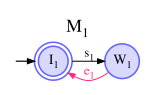

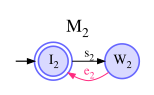

In [3]:
syms('I1 W1 I2 W2  s1 e1 s2 e2')
table1 = [(s1, 's_1'), (e1, 'e_1'), (s2, 's_2'), (e2, 'e_2'),
         (I1, 'I_1'), (W1, 'W_1'), (I2, 'I_2'), (W2, 'W_2')]

X1 = [I1, W1]
E1 = [s1, e1]
table1 = [(s1, 's_1'), (e1, 'e_1'),  (I1, 'I_1'), (W1, 'W_1')]
table2 = [(s2, 's_2'), (e2, 'e_2'), (I2, 'I_2'), (W2, 'W_2')]



X2 = [I2, W2]
E2 = [s2, e2]   
T1 = [(I1, s1, W1), (W1, e1, I1)]
T2 = [(I2, s2, W2), (W2, e2, I2)]
M1 = fsa(X1, E1, T1, [I1], [I1], table1, Sigcon=[s1], name='$M_1$')
M2 = fsa(X2, E2, T2, [I2], [I2], table2, Sigcon=[s2], name='$M_2$')
draw(M1, M2)

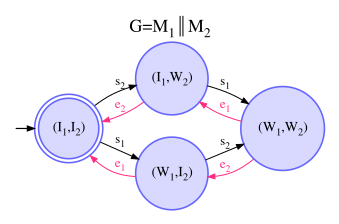

In [4]:
G = (M1 // M2).setpar(name='$G = M_1 \\parallel M_2$')
draw(G)


## 2. Especificación: buffer de capacidad 1

El buffer  $B$ tiene dos estados: $0$ (vacío) y $1$ (lleno). $b_1$ indica que $M_1$ deja una pieza y  $a_2$ indica que $M_2$ la retira.
Como $BE$ no tiene $b_1$ en el estado $1$ ni $a_2$ en el estado $0$, prohíbe el desborde y que
$M_2$ arranque sin pieza. 

$H = G \parallel B$ combina la planta con la especificación y marca el lenguaje deseado $K = L_m(H)$.


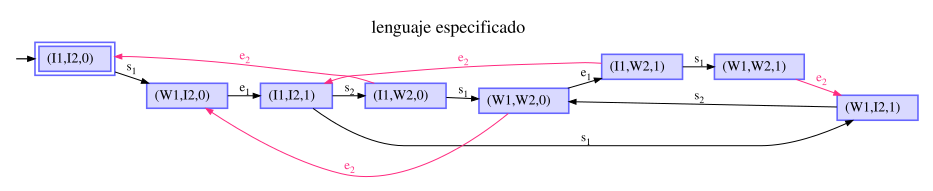

In [5]:
XB = [0, 1]
EB = [e1, s2]
TB = [(0, e1, 1), (1, s2, 0)]
tableB = [(e1, 'e_1'), (s2, 's_2')]
B = fsa(XB, EB, TB, [0], [0], table=tableB, name='$B$ -- bufer', type='specification')

H = (G // B).setpar(name='lenguaje especificado', style='verifier')
H = H.renamestates({((x1,x2),x3): (x1,x2,x3) for ((x1,x2),x3) in H.X })
draw(H)



## 3. ¿Es controlable $K$?

$K$ es controlable con respecto a $L(G)$ y a los eventos no controlables $\Sigma_{uc}$ si
$\overline{K}\,\Sigma_{uc} \cap L(G) \subseteq \overline{K}$: la especificación nunca debe prohibir un
evento no controlable que la planta puede ejecutar, porque el supervisor no lo puede impedir.
`iscontrollable(H, G)` hace esa prueba. La celda lista además los estados de $H$ donde falla.

In [6]:
print('¿K es controlable?', iscontrollable(H, G))

Sigma_uc = G.Sigma - G.Sigcon
for xh in sorted(H.X):
    m1 , m2 , b  = xh
    prohibidos = (G.Gamma((m1,m2)) & Sigma_uc) - H.Gamma(xh)
    if prohibidos:
        print(f'en el estado {xh} H prohíbe {sorted(prohibidos)}, que no es controlable')

¿K es controlable? False
en el estado ('W1', 'I2', 1) H prohíbe ['e1'], que no es controlable
en el estado ('W1', 'W2', 1) H prohíbe ['e1'], que no es controlable


En los dos estados la máquina 1 trabaja con el buffer lleno: cuando termine ($b_1$, no
controlable) el buffer se desborda, y el supervisor no lo puede evitar. Hay que actuar antes,
deshabilitando $a_1$ cuando el buffer está lleno. Eso es lo que calcula el sublenguaje
controlable supremo.

## 4. Supervisor: supremo sublenguaje controlable

`supcontrollable(H, G)` devuelve un autómata que marca $K^{\uparrow C}$, el mayor sublenguaje
controlable de $K$.

`supcontrollable` numera los estados. La función `con_estados_de` los renombra con el estado de $H$
que corresponde a cada uno, para leer el dibujo en términos de las máquinas y el buffer.

Using General Algorithm


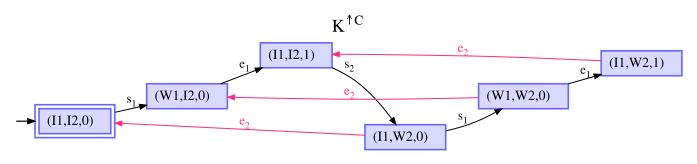

In [7]:
def include_states(S, H):
    """Renombra los estados de S (calculado a partir de H) con el estado
    de H que corresponde a cada uno."""
    map = {s: h for (s, h) in product(S, H).X}
    return S.renamestates(map).setpar(table=H.symDict, style='verifier')

S = supcontrollable(H, G, verbose=True)
S = include_states(S, H)
draw(S)

In [10]:
print('¿S es controlable?         ', iscontrollable(S, G))
print('¿Lm(S) ⊆ K?                ', S <= H)
print('¿S es no bloqueante (trim)?', S == trim(S))

¿S es controlable?          True
¿Lm(S) ⊆ K?                 True
¿S es no bloqueante (trim)? True


## 5. Acción de control

En cada estado del supervisor, los eventos que la planta puede ejecutar pero que $S$ no tiene definidos
son los que el supervisor deshabilita. Todos deben ser controlables.

In [11]:
def accion_de_control(S, G):
    """Para cada estado de S muestra los eventos habilitados y los que S
    deshabilita. Aplanado, un estado de S es (estados de G, estados de la
    especificación)."""
    aplanar = lambda s: tuple(c for e in s for c in aplanar(e)) if isinstance(s, tuple) else (s,)
    texto = lambda v: ','.join(map(str, v))  # los estados pueden ser números (buffer)
    planta = {aplanar(x): x for x in G.X}     # estado aplanado -> estado de G
    n = len(next(iter(planta)))               # componentes del estado de la planta
    print(f"{'planta':10}{'especif.':10}{'habilitados':24}deshabilitados")
    for s in sorted(S.X, key=aplanar):
        x, e = planta[aplanar(s)[:n]], aplanar(s)[n:]
        habilitados = S.Gamma(s)
        deshabilitados = G.Gamma(x) - habilitados
        assert deshabilitados <= G.Sigcon  # S sólo deshabilita eventos controlables
        print(f"{texto(aplanar(x)):10}{texto(e):10}{', '.join(sorted(habilitados)):24}"
              f"{', '.join(sorted(deshabilitados))}")

accion_de_control(S, G)

planta    especif.  habilitados             deshabilitados
I1,I2     0         s1                      s2
I1,I2     1         s2                      s1
I1,W2     0         e2, s1                  
I1,W2     1         e2                      s1
W1,I2     0         e1                      s2
W1,W2     0         e1, e2                  
